## Image Processing and Computer Vision - Assignment Module #2


Alessandro Teodori (0001247539) alessandro.teodori3@studio.unibo.it

Juan Guillermo Jaramillo Saa (0001217725) juan.jaramillosaa@studio.unibo.it

Ubalducci Michele (0001226810) michele.ubalducci@studio.unibo.it

# Part 2A: fine-tune a pretrained ResNet-18 with the training hyperparameters of Part 1

We fine-tune the ResNet-18 of PyTorch, pretrained on ImageNet-1K (V1), on the 100 aircraft variants of
FGVC-Aircraft. As the assignment requires for 2A, we train it with **exactly the training hyperparameters of the
best model of Part 1** (`res_3461`, the residual network with 31 convolutional layers), and nothing else
is tuned.

| hyperparameter | value (Part 1, best model) |
|---|---|
| resolution | 224 x 224 |
| epochs, batch size | 150 (the final, longer training of Part 1), 64 |
| optimizer | SGD, momentum 0.9 |
| learning rate, schedule | 0.05, one-cycle (rise over the first 30% of the epochs, then cosine decay) |
| weight decay | 5e-3 (convolution and linear weights only) |
| label smoothing | 0.2 |
| dropout | 0 |
| augmentation | random resized crop (50-100% of the area) + horizontal flip, random erasing (p = 0.25) |
| seeds | 42, 43, 44 |

The code is the one of Part 1 (`part1_ladder`): data pipeline, augmentation, training loop, experiment runner,
result storage and plots are copied unchanged. **The only differences** are:

1. the network: `torchvision.models.resnet18(weights=IMAGENET1K_V1)` with its 1000-way classifier replaced by a
   100-way one, instead of `AircraftNet`;
2. the input normalization: the pretrained weights expect the mean and standard deviation of ImageNet, not those of
   our training split.

**All choices are made on the validation split; test accuracy is only reported.**

## Setup

**How to run.** The notebook runs top to bottom on Colab (GPU runtime). The runs reported below are stored in the
repository (`results/part2A`) and are downloaded automatically: a run whose result already exists with the same
configuration is skipped, so tables and plots are reproduced without training. Setting `RETRAIN = True` trains
everything again. The results of Part 1 (`results/part1`), used as a reference, are downloaded too. If the official
dataset server is unavailable, the same archive is downloaded from a Kaggle mirror. On Colab, `USE_DRIVE = True`
keeps results and image cache in Google Drive; with `USE_DRIVE = False` everything stays on the temporary disk of
the session.

In [1]:
%pip install -q torchinfo kagglehub

In [2]:
import contextlib, json, math, random, sys, time
from pathlib import Path

import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.nn.functional as F
import torchinfo
from torchvision import datasets
from torchvision.models import resnet18, ResNet18_Weights
from torchvision.ops import roi_align
from torchvision.transforms import functional as TF
import matplotlib.pyplot as plt
from tqdm.auto import tqdm

IN_COLAB = "google.colab" in sys.modules
DEVICE = torch.device("cuda" if torch.cuda.is_available()
                      else "mps" if torch.backends.mps.is_available() else "cpu")

# Mixed precision on CUDA only: bfloat16 where supported (A100, L4), float16 + loss scaling otherwise (T4)
AMP = DEVICE.type == "cuda"
AMP_DTYPE = torch.bfloat16 if (AMP and torch.cuda.is_bf16_supported()) else torch.float16

RETRAIN = False        # True: retrain runs even if their JSON already exists
SHOW_SUMMARY = True    # print the model summary when a run starts with a different architecture than the last one
USE_DRIVE = False       # Colab only: keep results and image cache in Google Drive (False: Colab's temporary disk)
print(f"device: {DEVICE}" + (f" ({torch.cuda.get_device_name()})" if AMP else "")
      + f" | amp: {AMP_DTYPE if AMP else 'off'} | torch {torch.__version__}")

device: cuda (NVIDIA A100-SXM4-40GB) | amp: torch.bfloat16 | torch 2.11.0+cu130


### Paths

Same layout as Part 1: results and the preprocessed image cache are kept in Google Drive when `USE_DRIVE = True` and
on the temporary disk of the session otherwise; in both cases the stored results of the repository are downloaded
there before anything else. Locally, they are read from the repository itself. The image cache is the one of Part 1.

In [4]:
if IN_COLAB and USE_DRIVE:
    from google.colab import drive
    drive.mount("/content/drive")
    RESULTS_DIR = Path("/content/drive/MyDrive/ipcv/results/part2A")
    PART1_DIR = Path("/content/drive/MyDrive/ipcv/results/part1")
    CACHE_DIR = Path("/content/drive/MyDrive/ipcv/cache")
    DATA_ROOT = Path("/content/data")
elif IN_COLAB:
    # everything on the temporary disk of the session: no access to Google Drive is needed
    RESULTS_DIR = Path("/content/results/part2A")
    PART1_DIR = Path("/content/results/part1")
    CACHE_DIR = Path("/content/cache")
    DATA_ROOT = Path("/content/data")
else:
    REPO_DIR = Path.cwd().parent if Path.cwd().name == "code" else Path.cwd()
    RESULTS_DIR = REPO_DIR / "results" / "part2A"
    PART1_DIR = REPO_DIR / "results" / "part1"
    DATA_ROOT = Path.home() / "data" / "fgvc"
    CACHE_DIR = DATA_ROOT / "cache"

for d in (RESULTS_DIR, CACHE_DIR):
    d.mkdir(parents=True, exist_ok=True)
print("results ->", RESULTS_DIR)

GITHUB_REPO, GITHUB_REF = "jortikcode/100planes-X-IPCV", "main"   # a branch, or a tag to freeze the results
FETCH_RESULTS = IN_COLAB      # locally the repo already contains them


def fetch_results(repo, ref, dest, part):
    # Download the repo as one archive and copy its results/<part> JSON files into dest, never overwriting.
    import io, tarfile, urllib.request
    prefix = f"results/{part}/"
    with urllib.request.urlopen(f"https://github.com/{repo}/archive/{ref}.tar.gz") as response:
        archive = tarfile.open(fileobj=io.BytesIO(response.read()), mode="r:gz")
    added = kept = 0
    for member in archive.getmembers():
        path = member.name.split("/", 1)[-1]                 # drop the "<repo>-<ref>/" prefix
        name = path.rsplit("/", 1)[-1]
        if (not (member.isfile() and path.startswith(prefix) and name.endswith(".json"))
                or ".." in path or name.startswith(".")):
            continue
        target = dest / path[len(prefix):]
        if target.exists():
            kept += 1
            continue
        target.parent.mkdir(parents=True, exist_ok=True)
        target.write_bytes(archive.extractfile(member).read())
        added += 1
    print(f"results/{part} from github.com/{repo} ({ref}): {added} downloaded, {kept} already present")


if FETCH_RESULTS:
    for part, dest in (("part2A", RESULTS_DIR), ("part1", PART1_DIR)):
        try:
            fetch_results(GITHUB_REPO, GITHUB_REF, dest, part)
        except Exception as e:
            print(f"WARNING: could not download results/{part} ({e})")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
results -> /content/drive/MyDrive/ipcv/results/part2A
results/part2A from github.com/jortikcode/100planes-X-IPCV (main): 0 downloaded, 0 already present
results/part1 from github.com/jortikcode/100planes-X-IPCV (main): 9 downloaded, 129 already present


### Reproducibility

We seed every source of randomness (initialization, data order, augmentation) and keep cuDNN deterministic, so that a
configuration trained twice with the same seed gives the same result. Training a configuration with different seeds
is how we measure run-to-run noise.

In [5]:
def fix_random(seed):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.benchmark = False
    torch.backends.cudnn.deterministic = True


fix_random(42)

## Configuration

`BASE` holds the fixed choices of Part 1; `PART1_BEST` are the overrides that turn it into the best model of Part 1
(`res_3461`, configuration `cfg05`). The architecture keys of Part 1 (`channels`, `blocks`, `batchnorm`, ...) do not
apply here: the network is the pretrained ResNet-18.

In [6]:
BASE = dict(
    seed=42,
    # data
    img_size=224,
    augment=False,
    crop_scale=(0.5, 1.0),           # RandomResizedCrop: area of the crop, as a fraction of the image
    # architecture
    dropout=0.0,                     # before the classifier
    # training
    epochs=150,
    batch_size=64,
    lr=0.05,
    momentum=0.9,
    weight_decay=0.0,
    label_smoothing=0.0,
    random_erasing=0.0,              # probability of erasing a random rectangle
    warmup_epochs=3,
)

# The training hyperparameters of the best model of Part 1 (res_3461 with its tuned recipe, see part1_ladder)
PART1_BEST = dict(
    augment=True,
    crop_scale=(0.5, 1.0),
    dropout=0.0,
    epochs=150,
    lr=0.05,
    weight_decay=5e-3,
    label_smoothing=0.2,
    random_erasing=0.25,
    schedule="onecycle",
)

SEEDS = [42, 43, 44]

## Data

Same data as Part 1: FGVC-Aircraft (`torchvision.datasets.FGVCAircraft`, `annotation_level="variant"`), 100 classes,
3,334 / 3,333 / 3,333 images in train / val / test. The preprocessing (crop of the 20-pixel copyright banner, resize
to 224x224 without keeping the aspect ratio) and the GPU augmentation (random resized crop, horizontal flip, random
erasing) are those of Part 1, and so is the cache.

**Normalization.** The only change: Part 1 normalizes with the mean and standard deviation of our training split,
whereas the pretrained ResNet-18 was trained on inputs normalized with the **ImageNet statistics**
(`mean = (0.485, 0.456, 0.406)`, `std = (0.229, 0.224, 0.225)`), which is therefore the input distribution its
first layer expects.

In [7]:
BANNER_PX = 20
KAGGLE_MIRROR = "seryouxblaster764/fgvc-aircraft"     # public copy of the official fgvc-aircraft-2013b archive
IMAGENET_MEAN, IMAGENET_STD = (0.485, 0.456, 0.406), (0.229, 0.224, 0.225)


def fetch_from_kaggle(root):
    # Download the official archive from the Kaggle mirror and place it where torchvision's FGVCAircraft expects it.
    import kagglehub
    path = Path(kagglehub.dataset_download(KAGGLE_MIRROR))
    source = next((p for p in [path, *path.rglob("fgvc-aircraft-2013b")] if (p / "data" / "images").is_dir()), None)
    if source is None:
        raise RuntimeError(f"unexpected layout of the Kaggle mirror in {path}")
    target = root / "fgvc-aircraft-2013b"
    root.mkdir(parents=True, exist_ok=True)
    if target.is_symlink() or target.exists():
        if (target / "data" / "images").is_dir():
            return
        raise RuntimeError(f"{target} exists but is incomplete: remove it and run again")
    target.symlink_to(source, target_is_directory=True)


def build_cache(split, img_size):
    path = CACHE_DIR / f"{split}_{img_size}_stretch.pt"
    # an alternative file name for the same cache (same preprocessing: banner crop, stretch to a square)
    legacy = CACHE_DIR / f"{split}_{img_size}.pt"
    for p in (path, legacy):
        if p.exists():
            return torch.load(p)
    try:
        dset = datasets.FGVCAircraft(DATA_ROOT, split=split, annotation_level="variant", download=True)
    except Exception as official_error:
        # the official server is sometimes unavailable: same archive from the Kaggle mirror, still read by torchvision
        print(f"official download failed ({official_error}): using the Kaggle mirror {KAGGLE_MIRROR}")
        try:
            fetch_from_kaggle(DATA_ROOT)
            dset = datasets.FGVCAircraft(DATA_ROOT, split=split, annotation_level="variant", download=True)
        except Exception as e:
            raise RuntimeError(f"could not download FGVC-Aircraft, neither from the official server "
                               f"({official_error}) nor from Kaggle ({e})") from e
    images, labels = [], []
    for i in tqdm(range(len(dset)), desc=f"caching {split} @ {img_size}px"):
        img, label = dset[i]
        img = img.crop((0, 0, img.width, img.height - BANNER_PX))
        images.append(TF.pil_to_tensor(TF.resize(img, [img_size, img_size], antialias=True)))
        labels.append(label)
    cached = (torch.stack(images), torch.tensor(labels), dset.classes)
    torch.save(cached, path)
    return cached


class GPUSplit:
    # One split held on the device as uint8 images + labels.
    def __init__(self, split, img_size):
        x, y, self.classes = build_cache(split, img_size)
        self.x, self.y = x.to(DEVICE), y.to(DEVICE)

    def __len__(self):
        return len(self.y)


_DATA = {}


def get_data(img_size):
    # The three splits at one resolution, plus the normalization statistics expected by the pretrained network.
    if img_size not in _DATA:
        splits = {s: GPUSplit(s, img_size) for s in ("train", "val", "test")}
        mean = torch.tensor(IMAGENET_MEAN, device=DEVICE).view(1, 3, 1, 1)
        std = torch.tensor(IMAGENET_STD, device=DEVICE).view(1, 3, 1, 1)
        _DATA[img_size] = dict(splits, mean=mean, std=std)
    return _DATA[img_size]


def gpu_augment(x, size, scale=(0.5, 1.0), ratio=(3 / 4, 4 / 3)):
    # RandomResizedCrop + horizontal flip on a float batch, a different crop for every image.
    B, _, H, W = x.shape
    dev = x.device
    area = torch.empty(B, device=dev).uniform_(*scale) * H * W
    log_r = torch.empty(B, device=dev).uniform_(math.log(ratio[0]), math.log(ratio[1]))
    r = torch.exp(log_r)
    w = torch.sqrt(area * r).clamp(max=W)
    h = torch.sqrt(area / r).clamp(max=H)
    x0 = torch.rand(B, device=dev) * (W - w)
    y0 = torch.rand(B, device=dev) * (H - h)
    idx = torch.arange(B, device=dev, dtype=x.dtype)
    boxes = torch.stack([idx, x0, y0, x0 + w, y0 + h], dim=1)      # one box per image: (index, x1, y1, x2, y2)
    out = roi_align(x, boxes, output_size=size, aligned=True)      # crop every box and resize it to size x size
    flip = torch.rand(B, device=dev) < 0.5
    return torch.where(flip.view(B, 1, 1, 1), out.flip(-1), out)          # flip half of the images


def gpu_random_erasing(x, p, scale=(0.02, 0.33), ratio=(0.3, 3.3)):
    # RandomErasing on a normalized batch: with probability p, a random rectangle of each image is set to 0 (the mean).
    B, _, H, W = x.shape
    dev = x.device
    area = torch.empty(B, device=dev).uniform_(*scale) * H * W
    r = torch.exp(torch.empty(B, device=dev).uniform_(math.log(ratio[0]), math.log(ratio[1])))
    h = torch.sqrt(area * r).clamp(max=H).view(B, 1, 1)
    w = torch.sqrt(area / r).clamp(max=W).view(B, 1, 1)
    y0 = torch.rand(B, 1, 1, device=dev) * (H - h)
    x0 = torch.rand(B, 1, 1, device=dev) * (W - w)
    ys = torch.arange(H, device=dev).view(1, H, 1)
    xs = torch.arange(W, device=dev).view(1, 1, W)
    mask = (ys >= y0) & (ys < y0 + h) & (xs >= x0) & (xs < x0 + w)
    mask &= (torch.rand(B, 1, 1, device=dev) < p)
    return x.masked_fill(mask.unsqueeze(1), 0.0)


def batches(split, data, cfg, train):
    # Yields normalized (x, y) batches; train=True shuffles, drops the last partial batch and augments.
    n = len(split)
    order = torch.randperm(n).to(DEVICE) if train else torch.arange(n, device=DEVICE)
    bs = cfg["batch_size"] if train else 512
    for i in range(0, n, bs):
        idx = order[i:i + bs]
        if train and len(idx) < bs:
            break
        x = split.x[idx].float() / 255                                       # float batch, in [0, 1]
        if train and cfg["augment"]:
            x = gpu_augment(x, cfg["img_size"], scale=tuple(cfg["crop_scale"]))
        x = (x - data["mean"]) / data["std"]                                 # normalized batch
        if train and cfg["random_erasing"] > 0:
            x = gpu_random_erasing(x, cfg["random_erasing"])
        yield x.contiguous(memory_format=torch.channels_last), split.y[idx]

Six training images as the network receives them (top) and after crop and flip (bottom).

classes: 100 | train 3334 | val 3333 | test 3333


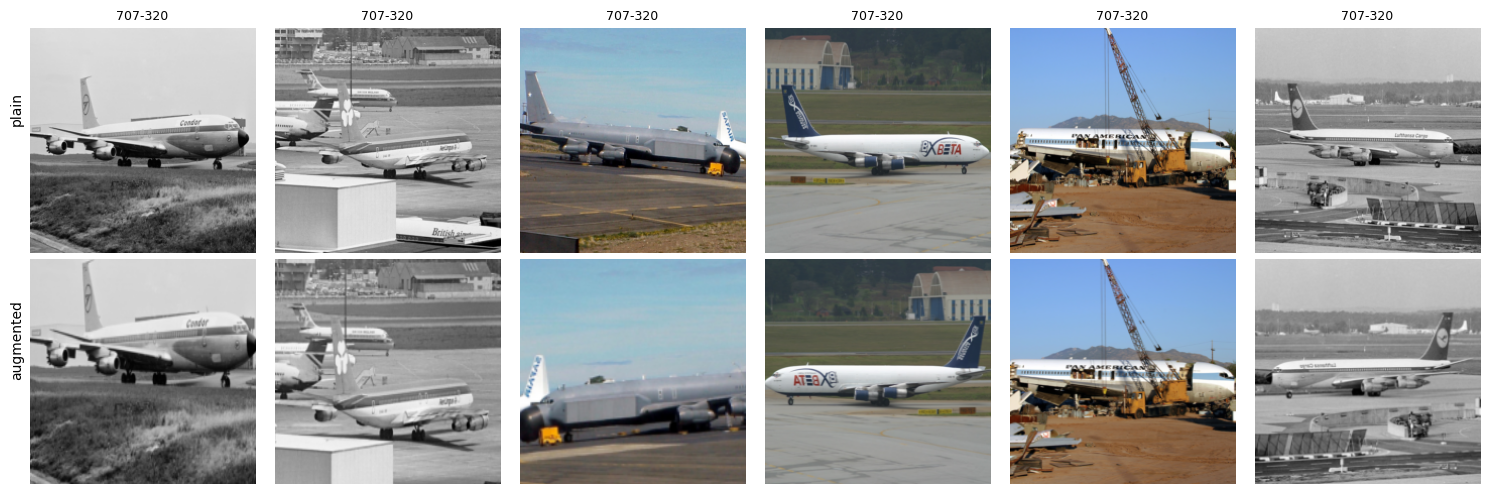

In [8]:
try:
    data = get_data(BASE["img_size"])
except Exception as e:
    data = None
    print(f"WARNING: the dataset is not available ({e})\n"
          "The cells that need the images are skipped; the stored results are still loaded and shown.")

N_CLASSES = 100                                   # FGVC-Aircraft, annotation_level="variant"
if data is not None:
    CLASSES = data["train"].classes
    assert len(CLASSES) == N_CLASSES
    print(f"classes: {N_CLASSES} | train {len(data['train'])} | val {len(data['val'])} | test {len(data['test'])}")

    fix_random(0)
    x = data["train"].x[:6].float() / 255
    rows = [x, gpu_augment(x, BASE["img_size"], scale=BASE["crop_scale"])]
    fig, axes = plt.subplots(2, 6, figsize=(15, 5))
    for r, imgs in enumerate(rows):
        for c in range(6):
            axes[r, c].imshow(imgs[c].permute(1, 2, 0).clamp(0, 1).cpu())
            axes[r, c].axis("off")
            if r == 0:
                axes[r, c].set_title(CLASSES[data["train"].y[c]], fontsize=9)
    axes[0, 0].text(-20, 80, "plain", rotation=90, va="center")
    axes[1, 0].text(-20, 80, "augmented", rotation=90, va="center")
    plt.tight_layout(); plt.show()

## The network

The ResNet-18 of PyTorch (`torchvision.models.resnet18`), initialized with the ImageNet-1K V1 weights
(`ResNet18_Weights.IMAGENET1K_V1`). It is a residual network like our best network of Part 1 (`res_3461`, `blocks = (3, 4, 6, 1)`),
with the stage layout of ResNet-18 (`blocks = (2, 2, 2, 2)`, 64 -> 512 channels, global average pooling), the original
7x7 convolution as stem, and every weight starting from ImageNet instead of a random initialization. The 1000-way classifier is replaced by a new `Dropout -> Linear(512, 100)`
(dropout is 0 here, as in Part 1), initialized at random. **All layers are fine-tuned**, with a single learning rate:
2A prescribes the hyperparameters of Part 1 and does not ask for anything else.

In [9]:
def build_model(cfg, n_classes=N_CLASSES):
    model = resnet18(weights=ResNet18_Weights.IMAGENET1K_V1)
    model.fc = nn.Sequential(nn.Dropout(cfg["dropout"]), nn.Linear(model.fc.in_features, n_classes))
    return model


def count_params(model):
    return sum(p.numel() for p in model.parameters())


def count_gflops(model, img_size):
    # Multiply-adds of convolutions and linear layers for one image, x2 = FLOPs.
    macs = 0

    def hook(m, inp, out):
        nonlocal macs
        if isinstance(m, nn.Conv2d):
            macs += out[0].numel() * (m.in_channels // m.groups) * m.kernel_size[0] * m.kernel_size[1]
        elif isinstance(m, nn.Linear):
            macs += m.in_features * m.out_features

    handles = [m.register_forward_hook(hook) for m in model.modules() if isinstance(m, (nn.Conv2d, nn.Linear))]
    with torch.no_grad():
        model.eval()(torch.zeros(1, 3, img_size, img_size))
    for h in handles:
        h.remove()
    return 2 * macs / 1e9

Layer-by-layer summary of the network (`torchinfo`); it is also printed at the start of the first run.

In [10]:
# the keys that define the architecture: two runs with the same values build the same network
ARCH_KEYS = ("img_size", "dropout")


def show_summary(cfg, depth=4):
    return torchinfo.summary(build_model(cfg), input_size=(1, 3, cfg["img_size"], cfg["img_size"]),
                             col_names=("output_size", "num_params"), row_settings=("var_names",),
                             depth=depth, device="cpu", verbose=0)


show_summary({**BASE, **PART1_BEST})

Downloading: "https://download.pytorch.org/models/resnet18-f37072fd.pth" to /root/.cache/torch/hub/checkpoints/resnet18-f37072fd.pth


100%|██████████| 44.7M/44.7M [00:00<00:00, 144MB/s] 


Layer (type (var_name))                  Output Shape              Param #
ResNet (ResNet)                          [1, 100]                  --
├─Conv2d (conv1)                         [1, 64, 112, 112]         9,408
├─BatchNorm2d (bn1)                      [1, 64, 112, 112]         128
├─ReLU (relu)                            [1, 64, 112, 112]         --
├─MaxPool2d (maxpool)                    [1, 64, 56, 56]           --
├─Sequential (layer1)                    [1, 64, 56, 56]           --
│    └─BasicBlock (0)                    [1, 64, 56, 56]           --
│    │    └─Conv2d (conv1)               [1, 64, 56, 56]           36,864
│    │    └─BatchNorm2d (bn1)            [1, 64, 56, 56]           128
│    │    └─ReLU (relu)                  [1, 64, 56, 56]           --
│    │    └─Conv2d (conv2)               [1, 64, 56, 56]           36,864
│    │    └─BatchNorm2d (bn2)            [1, 64, 56, 56]           128
│    │    └─ReLU (relu)                  [1, 64, 56, 56]           --
│

## Training

Identical to Part 1:

- **Optimizer**: SGD with momentum 0.9; weight decay applies to convolution and linear weights only, not to BN
  parameters and biases.
- **Schedule**: one-cycle, per epoch (Smith & Topin, 2019): cosine rise from lr/25 to lr over the first 30% of the
  epochs, then cosine decay to lr/1e4.
- **Loss**: cross-entropy with label smoothing. The validation loss is always plain cross-entropy.
- **Mixed precision** on CUDA (Micikevicius et al., ICLR 2018).
- **Model selection**: we keep the epoch with the highest validation accuracy and evaluate the test split once, on
  that checkpoint.

In [11]:
def autocast():
    return torch.autocast("cuda", dtype=AMP_DTYPE) if AMP else contextlib.nullcontext()


def make_optimizer(model, cfg):
    decay = [p for p in model.parameters() if p.ndim > 1]
    no_decay = [p for p in model.parameters() if p.ndim <= 1]
    return torch.optim.SGD([{"params": decay, "weight_decay": cfg["weight_decay"]},
                            {"params": no_decay, "weight_decay": 0.0}],
                           lr=cfg["lr"], momentum=cfg["momentum"])


def lr_at(epoch, cfg):
    if cfg.get("schedule", "cosine") == "onecycle":
        # one-cycle (Smith & Topin, 2019), per epoch: cosine rise from lr/25 to lr over the first 30% of the
        # epochs, then cosine decay to lr/1e4 (the defaults of torch.optim.lr_scheduler.OneCycleLR)
        up = max(round(0.3 * cfg["epochs"]), 1)
        low, high, end = cfg["lr"] / 25, cfg["lr"], cfg["lr"] / 1e4
        if epoch < up:
            return high + (low - high) * (1 + math.cos(math.pi * epoch / up)) / 2
        t = (epoch - up) / max(cfg["epochs"] - up, 1)
        return end + (high - end) * (1 + math.cos(math.pi * t)) / 2
    if epoch < cfg["warmup_epochs"]:
        return cfg["lr"] * (epoch + 1) / cfg["warmup_epochs"]
    progress = (epoch - cfg["warmup_epochs"]) / max(cfg["epochs"] - cfg["warmup_epochs"], 1)
    return cfg["lr"] * 0.5 * (1 + math.cos(math.pi * progress))


def train_epoch(model, opt, scaler, criterion, data, cfg):
    model.train()
    total_loss = torch.zeros((), device=DEVICE)
    correct = torch.zeros((), device=DEVICE)
    n = 0
    for x, y in batches(data["train"], data, cfg, train=True):
        with autocast():
            logits = model(x)
            loss = criterion(logits, y)
        opt.zero_grad(set_to_none=True)
        scaler.scale(loss).backward()
        scaler.step(opt)
        scaler.update()
        total_loss += loss.detach().float() * len(y)
        correct += (logits.argmax(1) == y).sum()
        n += len(y)
    return total_loss.item() / n, correct.item() / n


@torch.no_grad()
def evaluate(model, split, data, cfg, return_preds=False):
    model.eval()
    total_loss, correct, preds = 0.0, 0, []
    for x, y in batches(split, data, cfg, train=False):
        with autocast():
            logits = model(x)
        total_loss += F.cross_entropy(logits.float(), y, reduction="sum").item()
        p = logits.argmax(1)
        correct += (p == y).sum().item()
        if return_preds:
            preds.append(p.cpu())
    n = len(split)
    out = (total_loss / n, correct / n)
    return out + (torch.cat(preds).tolist(),) if return_preds else out


def fit(cfg, data, verbose=True):
    model = build_model(cfg).to(DEVICE).to(memory_format=torch.channels_last)
    opt = make_optimizer(model, cfg)
    scaler = torch.amp.GradScaler("cuda", enabled=AMP and AMP_DTYPE == torch.float16)
    criterion = nn.CrossEntropyLoss(label_smoothing=cfg["label_smoothing"])
    hist = {k: [] for k in ("train_loss", "train_acc", "val_loss", "val_acc", "lr", "seconds")}
    best_acc, best_epoch, best_state, diverged = -1.0, 0, None, False

    for epoch in range(cfg["epochs"]):
        t0 = time.time()
        lr = lr_at(epoch, cfg)
        for g in opt.param_groups:
            g["lr"] = lr
        tr_loss, tr_acc = train_epoch(model, opt, scaler, criterion, data, cfg)
        if not math.isfinite(tr_loss):
            diverged = True
            print(f"  diverged at epoch {epoch + 1} (training loss {tr_loss})")
            break
        va_loss, va_acc = evaluate(model, data["val"], data, cfg)
        for k, v in zip(hist, (tr_loss, tr_acc, va_loss, va_acc, lr, time.time() - t0)):
            hist[k].append(v)
        if va_acc > best_acc:
            best_acc, best_epoch = va_acc, epoch + 1
            best_state = {k: v.detach().clone() for k, v in model.state_dict().items()}
        if verbose and (epoch % 5 == 0 or epoch == cfg["epochs"] - 1):
            print(f"  ep {epoch + 1:3d} | lr {lr:.4f} | train loss {tr_loss:.3f} acc {tr_acc:.3f} "
                  f"| val loss {va_loss:.3f} acc {va_acc:.3f} | {hist['seconds'][-1]:.1f}s")

    if best_state is not None:
        model.load_state_dict(best_state)
    return model, hist, best_epoch, diverged

## Experiment runner

`run_experiment` trains one configuration, evaluates its best checkpoint on the test split and stores the
configuration, the per-epoch curves and the test predictions in `results/part2A`, exactly as in Part 1. A run whose
result already exists with the same configuration is skipped. 2A has no learning-rate sweep (the learning rate is the
one of Part 1), so every seed is trained at the same configuration and the mean over the seeds is not biased by a
selection.

In [12]:
def result_path(name, group, seed):
    return RESULTS_DIR / group / f"{name}_seed{seed}.json"


_last_arch = None


def run_experiment(name, group, note="", **overrides):
    global _last_arch
    cfg = {**BASE, **overrides, "name": name, "group": group}
    out = result_path(name, group, cfg["seed"])
    if out.exists() and not RETRAIN:
        run = json.loads(out.read_text())
        if run["config"] == json.loads(json.dumps(cfg)):      # same configuration (tuples stored as lists)
            print(f"skip {group}/{name}: best val {run['best_val_acc']:.3f} (already trained)")
            return run
        print(f"{group}/{name}: configuration changed since the stored run, training again")

    print(f"### {group}/{name}")
    print("    " + " | ".join(f"{k} {cfg[k]}" for k in ("lr", "weight_decay", "label_smoothing", "dropout",
                                                        "random_erasing", "augment", "crop_scale", "seed", "epochs"))
          + f" | schedule {cfg.get('schedule', 'cosine')}")
    arch = {k: cfg[k] for k in ARCH_KEYS}
    if SHOW_SUMMARY and arch != _last_arch:
        print(show_summary(cfg))
        _last_arch = arch
    fix_random(cfg["seed"])
    data = get_data(cfg["img_size"])
    t0 = time.time()
    model, hist, best_epoch, diverged = fit(cfg, data)
    minutes = (time.time() - t0) / 60
    if best_epoch:
        test_loss, test_acc, test_pred = evaluate(model, data["test"], data, cfg, return_preds=True)
    else:   # diverged before the first validation: there is no checkpoint to test
        test_loss, test_acc, test_pred = float("nan"), float("nan"), []

    cpu_model = build_model(cfg)
    run = dict(
        name=name, group=group, seed=cfg["seed"], note=note, config=cfg, history=hist,
        best_val_acc=max(hist["val_acc"], default=0.0), best_epoch=best_epoch,
        final_val_acc=hist["val_acc"][-1] if hist["val_acc"] else 0.0,
        final_train_acc=hist["train_acc"][-1] if hist["train_acc"] else 0.0,
        test_acc=test_acc, test_loss=test_loss, test_pred=test_pred,
        test_true=data["test"].y.cpu().tolist(),
        params=count_params(cpu_model), gflops=count_gflops(cpu_model, cfg["img_size"]),
        minutes=minutes, device=torch.cuda.get_device_name() if AMP else str(DEVICE), diverged=diverged,
    )
    out.parent.mkdir(parents=True, exist_ok=True)
    out.write_text(json.dumps(run))
    print(f"{name}: best val {run['best_val_acc']:.3f} (epoch {best_epoch}) | test {test_acc:.3f} | {minutes:.1f} min")
    return run


def load_group(group, results_dir=None):
    runs = [json.loads(p.read_text()) for p in sorted(((results_dir or RESULTS_DIR) / group).glob("*.json"))]
    return {r["name"]: r for r in runs}


def seed_mean(runs, key="best_val_acc"):
    return float(np.mean([r[key] for r in runs]))


def seed_std(runs, key="best_val_acc"):
    return float(np.std([r[key] for r in runs], ddof=1)) if len(runs) > 1 else float("nan")

## 2A: fine-tuning with the hyperparameters of Part 1

The whole ResNet-18 is fine-tuned with the training hyperparameters of the best model of Part 1 (table above), with
three seeds. The learning rate of 0.05 was tuned for a network trained from scratch; this experiment shows how
it behaves on pretrained weights, which is the starting point of 2B.

In [13]:
# [run]
for seed in SEEDS:
    run_experiment(f"resnet18_ft_s{seed}", "finetune", note="part 1 best hyperparameters", seed=seed, **PART1_BEST)

### finetune/resnet18_ft_s42
    lr 0.05 | weight_decay 0.005 | label_smoothing 0.2 | dropout 0.0 | random_erasing 0.25 | augment True | crop_scale (0.5, 1.0) | seed 42 | epochs 150 | schedule onecycle
Layer (type (var_name))                  Output Shape              Param #
ResNet (ResNet)                          [1, 100]                  --
├─Conv2d (conv1)                         [1, 64, 112, 112]         9,408
├─BatchNorm2d (bn1)                      [1, 64, 112, 112]         128
├─ReLU (relu)                            [1, 64, 112, 112]         --
├─MaxPool2d (maxpool)                    [1, 64, 56, 56]           --
├─Sequential (layer1)                    [1, 64, 56, 56]           --
│    └─BasicBlock (0)                    [1, 64, 56, 56]           --
│    │    └─Conv2d (conv1)               [1, 64, 56, 56]           36,864
│    │    └─BatchNorm2d (bn1)            [1, 64, 56, 56]           128
│    │    └─ReLU (relu)                  [1, 64, 56, 56]           --
│    │    └─Co

## Results

All tables and plots below are computed from the stored runs.

In [14]:
# Categorical colours in a fixed order (one per run inside a plot)
COLORS = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300", "#6250d6", "#e34948"]
plt.rcParams.update({"axes.prop_cycle": plt.cycler(color=COLORS), "lines.linewidth": 2,
                     "axes.grid": True, "grid.alpha": 0.3, "axes.spines.top": False, "axes.spines.right": False})


def summary(runs):
    # One row per run (single seed).
    rows = [dict(run=n, lr=r["config"]["lr"], params_M=r["params"] / 1e6, best_val=r["best_val_acc"],
                 best_epoch=r["best_epoch"], final_train=r["final_train_acc"],
                 gap=r["final_train_acc"] - r["final_val_acc"], test=r["test_acc"], minutes=r["minutes"])
            for n, r in runs.items()]
    return pd.DataFrame(rows).set_index("run").style.format(
        {"lr": "{:g}", "params_M": "{:.2f}", "best_val": "{:.3f}", "final_train": "{:.3f}", "gap": "{:+.3f}",
         "test": "{:.3f}", "minutes": "{:.1f}"})


def seed_summary(groups):
    # One row per configuration, mean ± std over the seeds. groups: {label: [runs]}
    rows = [dict(run=label, lr=runs[0]["config"]["lr"], seeds=len(runs), params_M=runs[0]["params"] / 1e6,
                 val_mean=seed_mean(runs), val_std=seed_std(runs),
                 test_mean=seed_mean(runs, "test_acc"), test_std=seed_std(runs, "test_acc"),
                 train_mean=seed_mean(runs, "final_train_acc"))
            for label, runs in groups.items() if runs]
    return pd.DataFrame(rows).set_index("run").style.format(
        {"lr": "{:g}", "params_M": "{:.2f}", "val_mean": "{:.3f}", "val_std": "{:.3f}", "test_mean": "{:.3f}",
         "test_std": "{:.3f}", "train_mean": "{:.3f}"})


def plot_curves(runs, title=""):
    # Validation accuracy, validation loss (plain CE) and training accuracy against the epoch.
    fig, axes = plt.subplots(1, 3, figsize=(17, 4.5))
    for i, (name, r) in enumerate(runs.items()):
        h = r["history"]
        ep = range(1, len(h["val_acc"]) + 1)
        c = COLORS[i % len(COLORS)]
        axes[0].plot(ep, h["val_acc"], color=c, label=name)
        if r["best_epoch"]:
            axes[0].plot(r["best_epoch"], r["best_val_acc"], "o", color=c, markersize=7)
        axes[1].plot(ep, h["val_loss"], color=c, label=name)
        axes[2].plot(ep, h["train_acc"], color=c, label=name)
    for ax, t in zip(axes, ("validation accuracy (dot = best epoch)", "validation loss (plain CE)",
                            "training accuracy")):
        ax.set_title(t); ax.set_xlabel("epoch")
    axes[0].legend(fontsize=8)
    fig.suptitle(title); plt.tight_layout(); plt.show()

### Fine-tuned ResNet-18 vs. the best model of Part 1

Mean ± standard deviation over three seeds (`resnet18_ft`: pretrained ResNet-18, `res_3461`: our best
network, trained from scratch in Part 1 with the same hyperparameters). The curves are the seed-42 runs.

,lr,seeds,params_M,val_mean,val_std,test_mean,test_std,train_mean
run,,,,,,,,
"resnet18_ft (pretrained, 2A)",0.05,3,11.23,0.719,0.007,0.724,0.007,0.993
"res_3461 (from scratch, part 1)",0.05,3,11.91,0.740,0.007,0.742,0.002,0.982


resnet18_ft (pretrained, 2A)     val 0.719 ± 0.007 | test 0.724 ± 0.007 | train 0.993
res_3461 (from scratch, part 1)  val 0.740 ± 0.007 | test 0.742 ± 0.002 | train 0.982


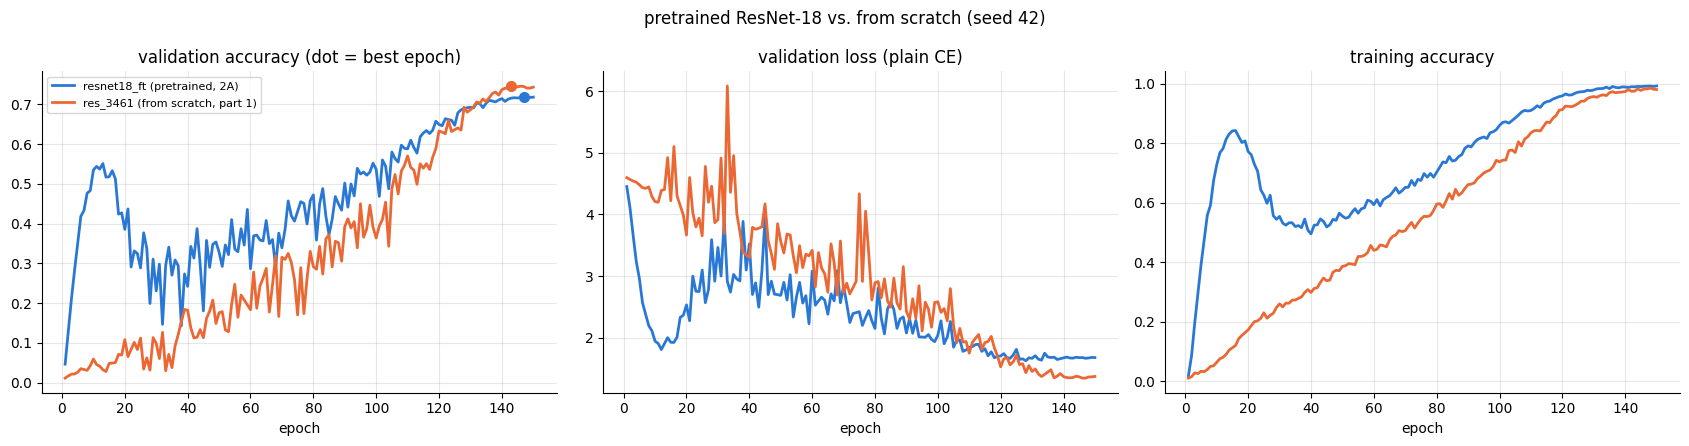

In [17]:
ft_runs = [r for n, r in sorted(load_group("finetune").items())]
part1_runs = []
if PART1_DIR.exists():
    long = load_group("long", PART1_DIR)         # the 150-epoch trainings of Part 1
    part1_runs = [long[f"res_3461_ep{BASE['epochs']}_s{s}"] for s in SEEDS if f"res_3461_ep{BASE['epochs']}_s{s}" in long]
    if not part1_runs:
        print("WARNING: the 150-epoch runs of Part 1 (results/part1/long) are not available: no reference shown")

groups = {"resnet18_ft (pretrained, 2A)": ft_runs, "res_3461 (from scratch, part 1)": part1_runs}
groups = {k: v for k, v in groups.items() if v}
if groups:
    display(seed_summary(groups))
    for label, runs in groups.items():
        print(f"{label:32s} val {seed_mean(runs):.3f} ± {seed_std(runs):.3f} | "
              f"test {seed_mean(runs, 'test_acc'):.3f} ± {seed_std(runs, 'test_acc'):.3f} | "
              f"train {seed_mean(runs, 'final_train_acc'):.3f}")
    plot_curves({label: runs[0] for label, runs in groups.items()}, "pretrained ResNet-18 vs. from scratch (seed 42)")
else:
    print("no stored run yet: run the 2A cell above")

### Single runs

One row per seed of the fine-tuning, with the epoch of the best validation accuracy, the training accuracy at the
last epoch and the train-validation gap.

,lr,params_M,best_val,best_epoch,final_train,gap,test,minutes
run,,,,,,,,
resnet18_ft_s42,0.05,11.23,0.719,147,0.992,+0.274,0.724,2.2
resnet18_ft_s43,0.05,11.23,0.726,146,0.993,+0.271,0.731,2.2
resnet18_ft_s44,0.05,11.23,0.712,143,0.995,+0.286,0.718,2.2


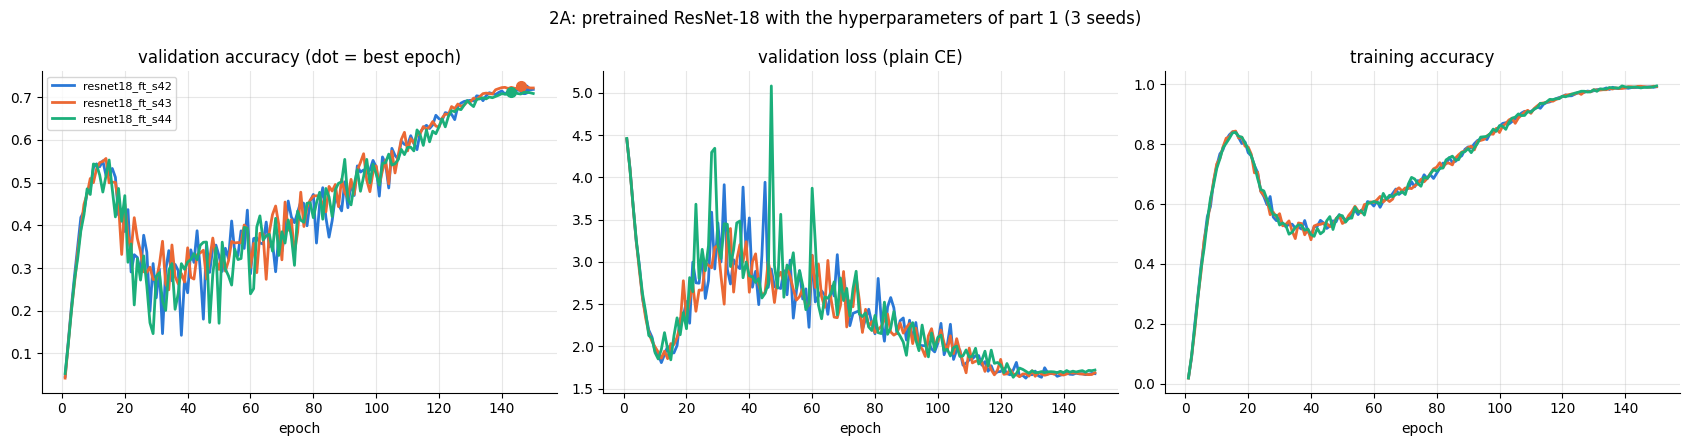

In [18]:
finetune = load_group("finetune")
if finetune:
    display(summary(finetune))
    plot_curves(finetune, "2A: pretrained ResNet-18 with the hyperparameters of part 1 (3 seeds)")